NAMA : Rida Tsaniya Putri Hamdani

NIM : 2404010005

1. Later belakang dan Permasalahan

Studi Kasus : filter SMS Spam

SMS spam adalah pesan teks yang tidak diminta, biasanya berisi iklan , penipunan berhadiah, tautan berbahya (phishing) atau ajakan menghubungi nomer berbayar. di indonesia bentuk umumnya adaah SMS "Selamat Anda menang undian" atau pinjaman online ilegal.

Permasalahan yang dihadapi:


*   jumlah pesan sangat besar shingga tidak mungkin disaring secara manual
*   aturan sederhana misalnya blokir kata "gratis" mudah dikelabuhi dan sering salah blokir pesan yng sah


*   dua jenis kesalahan punya dampak berbeda spam lolos menunggu dan berisko penipuan sedangkan pesan yang sah malah diblokir sehingga pengguna kehilangan pesan penting seperi kode OTP





2. Metode Klasifikasi yang Digunakan

Teks tidak bisa langsung diproses model, sehingga diubah menjadi angka dengan TF-IDF (Term Frequency - Inverse Document Frequency), yaitu pembobotan yang memberi nilai tinggi pada kata yang sering muncul di sebuah pesan tetapi jarang di pesan lain.

Tiga algoritma dibandingkan:

| Algoritma | Ide Singkat | Alasan Dipilih |
|---|---|---|
| **Multinomial Naive Bayes** | Probabilitas kelas berdasarkan frekuensi kata, dengan asumsi kata saling bebas. | Cepat, sederhana, dan menjadi baseline klasik untuk filter spam. |
| **Logistic Regression** | Model linear yang menghasilkan probabilitas spam. | Mudah ditafsirkan untuk mengetahui kata mana yang paling menandai spam. |
| **Linear SVM** | Mencari batas pemisah (*hyperplane*) dengan margin terbesar. | Biasanya kuat pada data teks berdimensi tinggi. |

 3. Dataset

SMS Spam Collection (Almeida, Hidalgo & Yamakami, 2011), tersedia di UCI Machine Learning Repository dan Kaggle.

Kolom v1: label (ham atau spam).

Kolom v2: isi pesan SMS (bahasa Inggris).

Tiga kolom Unnamed hanya berisi sisa data kosong dan akan dibuang.

4. Penerapan

In [1]:
## import library dan memuat data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

Memuat library untuk olah data, grafik, dan model klasifikasi.

In [2]:
## Memuat Dataset
url = "https://raw.githubusercontent.com/Rida06-sud/Tugas-Klasifikasi-SMS-Spam/main/spam.csv"
df = pd.read_csv(url, encoding="latin-1")
print("Ukuran data mentah:", df.shape)
df.head()

Ukuran data mentah: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


os.path.exists(PATH) mengecek apakah file spam.csv sudah ada. Kalau belum,
files.upload() memunculkan kotak upload (khusus Colab).


encoding="latin-1" dipakai karena file ini bukan UTF-8. Kalau tidak, bisa muncul error karakter.


df.shape menampilkan (jumlah baris, jumlah kolom), dan df.head() menampilkan 5 baris pertama.


In [3]:
## Buang kolom kosong dan beri nama kolom yang jelas
df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "pesan"})

print("Nilai kosong per kolom:")
print(df.isna().sum(), "\n")
print("Jumlah baris duplikat:", df.duplicated().sum())
print("\nDistribusi kelas (data mentah):")
print(df["label"].value_counts())

Nilai kosong per kolom:
label    0
pesan    0
dtype: int64 

Jumlah baris duplikat: 403

Distribusi kelas (data mentah):
label
ham     4825
spam     747
Name: count, dtype: int64


Ukuran setelah duplikat dibuang: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     87.37 %
spam    12.63 %
Name: count, dtype: object


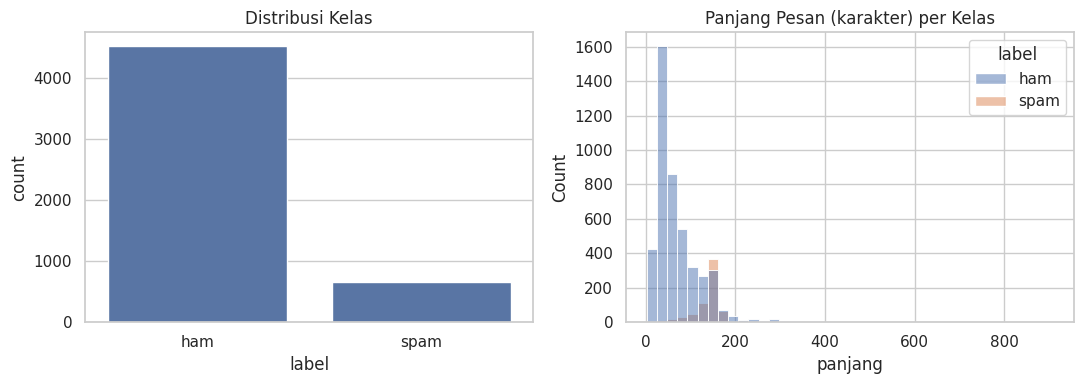

        count   mean   std   min    25%    50%    75%    max
label                                                       
ham    4516.0   70.5  56.4   2.0   34.0   52.0   90.0  910.0
spam    653.0  137.9  30.1  13.0  132.0  149.0  157.0  224.0


In [4]:
## Membersihkan data dari yang sama (duplicat)
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran setelah duplikat dibuang:", df.shape)

counts = df["label"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="label", order=["ham", "spam"], ax=ax[0])
ax[0].set_title("Distribusi Kelas")

df["panjang"] = df["pesan"].str.len()
sns.histplot(data=df, x="panjang", hue="label", bins=40, kde=False, ax=ax[1])
ax[1].set_title("Panjang Pesan (karakter) per Kelas")
plt.tight_layout()
plt.show()

print(df.groupby("label")["panjang"].describe().round(1))

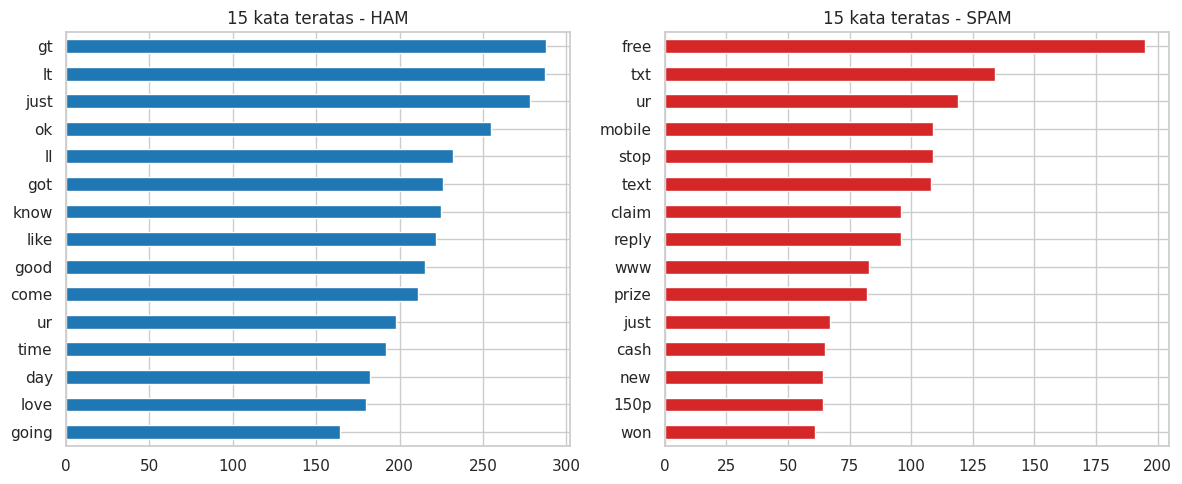

In [5]:
## Kata paling sering muncul pada masing-masing kelas
from sklearn.feature_extraction.text import CountVectorizer

def top_words(label, n=15):
    cv = CountVectorizer(stop_words="english")
    X = cv.fit_transform(df.loc[df["label"] == label, "pesan"])
    freq = np.asarray(X.sum(axis=0)).ravel()
    idx = freq.argsort()[::-1][:n]
    return pd.Series(freq[idx], index=cv.get_feature_names_out()[idx])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
top_words("ham").sort_values().plot.barh(ax=ax[0], color="tab:blue")
ax[0].set_title("15 kata teratas - HAM")
top_words("spam").sort_values().plot.barh(ax=ax[1], color="tab:red")
ax[1].set_title("15 kata teratas - SPAM")
plt.tight_layout()
plt.show()

In [6]:
## Membagi data latih dan uji
df["y"] = (df["label"] == "spam").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    df["pesan"], df["y"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df["y"]
)

print("Data latih:", X_train.shape[0], "| spam:", y_train.sum(), f"({y_train.mean():.1%})")
print("Data uji  :", X_test.shape[0],  "| spam:", y_test.sum(),  f"({y_test.mean():.1%})")

Data latih: 4135 | spam: 522 (12.6%)
Data uji  : 1034 | spam: 131 (12.7%)


In [7]:
## Membuat dan melatih model
def make_tfidf():
    return TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2)

models = {
    "Naive Bayes": Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB(alpha=0.1))]),
    "Logistic Regression": Pipeline([("tfidf", make_tfidf()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Linear SVM": Pipeline([("tfidf", make_tfidf()),
        ("clf", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))]),
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print("Selesai melatih:", name)

Selesai melatih: Naive Bayes
Selesai melatih: Logistic Regression
Selesai melatih: Linear SVM


In [8]:
## Evaluasi Model
rows, preds = [], {}
for name, pipe in models.items():
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (spam)": precision_score(y_test, y_pred),
        "Recall (spam)": recall_score(y_test, y_pred),
        "F1 (spam)": f1_score(y_test, y_pred),
    })

hasil = pd.DataFrame(rows).set_index("Model").round(4)
hasil

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Naive Bayes,0.9826,0.9748,0.8855,0.9280
Logistic Regression,0.9768,0.9280,0.8855,0.9062
Linear SVM,0.9807,0.9664,0.8779,0.9200


Menguji ketiga model pada data uji, lalu membandingkan accuracy, precision, recall, dan F1 dalam satu tabel.

In [9]:
## Validasi silang 5-fold (F1 kelas spam) untuk memastikan hasil stabil
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, pipe in models.items():
    s = cross_val_score(pipe, df["pesan"], df["y"], cv=skf, scoring="f1")
    cv_rows.append({"Model": name, "F1 rata-rata": s.mean(), "Std": s.std()})
pd.DataFrame(cv_rows).set_index("Model").round(4)

,F1 rata-rata,Std
Model,,
Naive Bayes,0.9291,0.0089
Logistic Regression,0.9162,0.0140
Linear SVM,0.9308,0.0135


Menguji kestabilan model dengan 5-fold cross validation. F1 rata-rata dan simpangannya menunjukkan apakah hasil model konsisten.

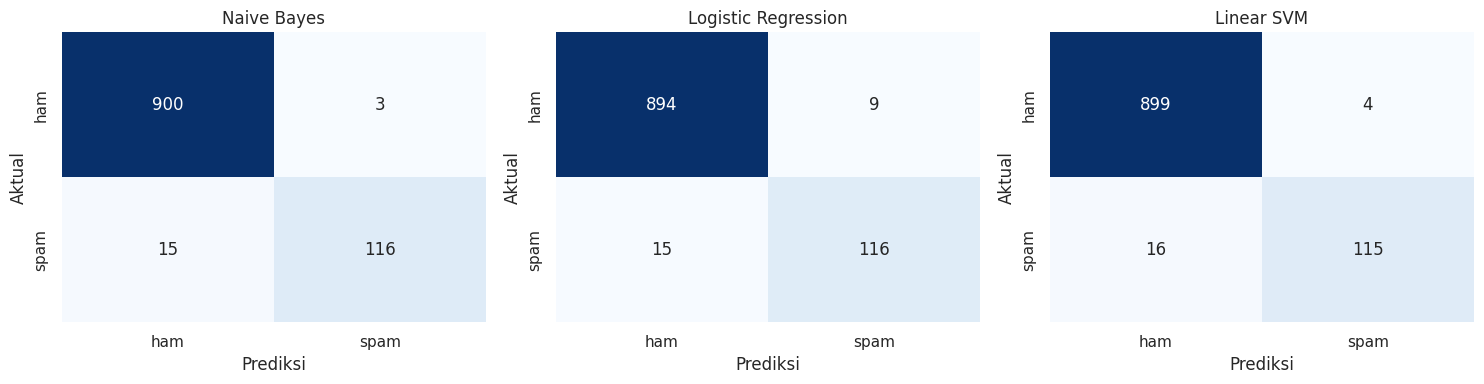

In [10]:
## Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

Menampilkan jumlah tebakan benar dan salah tiap model, termasuk pesan sah yang salah diblokir dan spam yang lolos.

In [11]:
## Model Terbaik dan Laporan Klasifikasi
BEST = hasil["F1 (spam)"].idxmax()
print("Model terbaik berdasarkan F1 (spam):", BEST, "\n")
print(classification_report(y_test, preds[BEST], target_names=["ham", "spam"], digits=4))

cm = confusion_matrix(y_test, preds[BEST])
tn, fp, fn, tp = cm.ravel()
print(f"Pesan sah salah diblokir (False Positive): {fp}")
print(f"Spam yang lolos (False Negative)        : {fn}")

Model terbaik berdasarkan F1 (spam): Naive Bayes 

              precision    recall  f1-score   support

         ham     0.9836    0.9967    0.9901       903
        spam     0.9748    0.8855    0.9280       131

    accuracy                         0.9826      1034
   macro avg     0.9792    0.9411    0.9590      1034
weighted avg     0.9825    0.9826    0.9822      1034

Pesan sah salah diblokir (False Positive): 3
Spam yang lolos (False Negative)        : 15


Memilih model dengan F1 (spam) tertinggi, lalu menampilkan laporan per kelas serta jumlah pesan sah yang salah diblokir dan spam yang lolos.

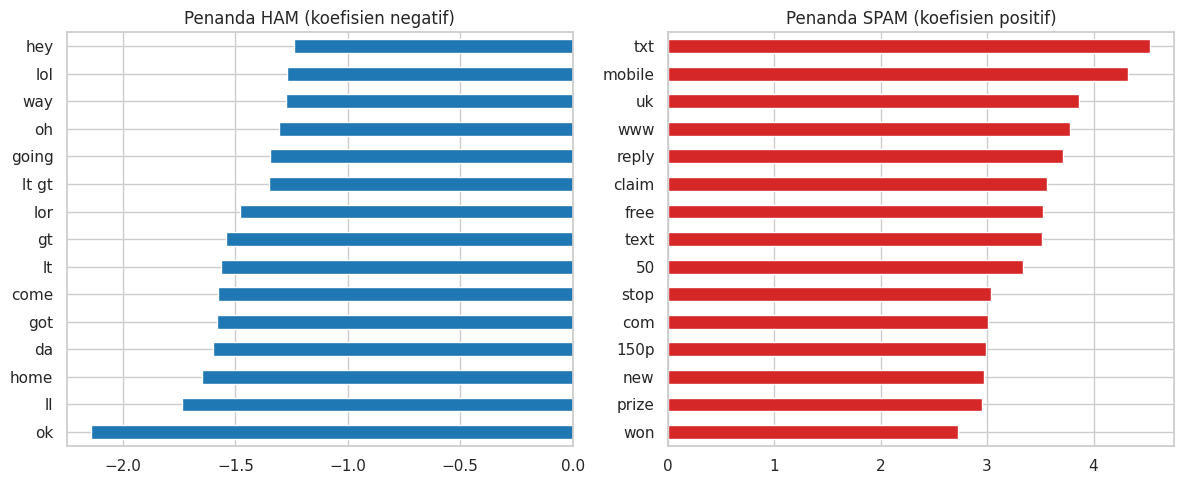

In [12]:
## Kata Penanda Spam dan Ham
lr = models["Logistic Regression"]
vec, clf = lr.named_steps["tfidf"], lr.named_steps["clf"]
fitur = np.array(vec.get_feature_names_out())
koef = clf.coef_[0]
order = koef.argsort()

top_spam = pd.Series(koef[order[-15:]], index=fitur[order[-15:]])
top_ham = pd.Series(koef[order[:15]], index=fitur[order[:15]])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
top_ham.plot.barh(ax=ax[0], color="tab:blue"); ax[0].set_title("Penanda HAM (koefisien negatif)")
top_spam.plot.barh(ax=ax[1], color="tab:red"); ax[1].set_title("Penanda SPAM (koefisien positif)")
plt.tight_layout()
plt.show()

Melihat 15 kata yang paling kuat menandai spam dan ham berdasarkan koefisien Logistic Regression.

In [13]:
##  Uji Pesan Baru
contoh = [
    "Congratulations! You have won a $1000 gift card. Call 0900123456 now to claim your prize",
    "URGENT! Your mobile number has been selected for a FREE holiday. Text WIN to 80082",
    "Hey, are we still meeting for lunch at 12 tomorrow?",
    "Can you send me the notes from today's class? Thanks!",
    "Free entry in 2 a weekly competition to win FA Cup tickets. Text FA to 87121 to receive entry",
]

model_final = models[BEST]
if hasattr(model_final.named_steps["clf"], "predict_proba"):
    prob = model_final.predict_proba(contoh)[:, 1]
else:
    prob = model_final.decision_function(contoh)

pred = model_final.predict(contoh)
pd.DataFrame({"Pesan": contoh,
              "Prediksi": np.where(pred == 1, "SPAM", "HAM"),
              "Skor spam": np.round(prob, 3)})

,Pesan,Prediksi,Skor spam
0,Congratulations! You have won a $1000 gift car...,SPAM,0.999
1,URGENT! Your mobile number has been selected f...,SPAM,0.995
2,"Hey, are we still meeting for lunch at 12 tomo...",HAM,0.002
3,Can you send me the notes from today's class? ...,HAM,0.006
4,Free entry in 2 a weekly competition to win FA...,SPAM,0.998


Mencoba model terbaik pada lima contoh pesan baru. Hasilnya berupa prediksi SPAM atau HAM beserta skor probabilitas spam.

REFERENSI

Almeida, T. & Gómez Hidalgo, J. (2011). SMS Spam Collection [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/228/sms+spam+collection
KDnuggets (2011). New dataset released: SMS Spam Collection v.1. https://www.kdnuggets.com/2011/06/sms-spam-collection-data.html

Manning, C. D., Raghavan, P., & Schütze, H. (2008). Introduction to Information Retrieval. Cambridge University Press. https://nlp.stanford.edu/IR-book/html/htmledition/naive-bayes-text-classification-1.html

Cortes, C., & Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), 273-297.

Fan, R.-E., et al. (2008). LIBLINEAR: A library for large linear classification. Journal of Machine Learning Research, 9, 1871-1874.

Spärck Jones, K. (1972). A statistical interpretation of term specificity and its application in retrieval. Journal of Documentation, 28(1), 11-21.